# Supplementary Fig S4 · Cross-platform search: platform shift and tissue agreement

The parts of the old Fig 5 (`_backup_2026-11-01/F5_cross_platform.ipynb`) that are not in the main Fig 3 (the two
sections and the Visium example are main Fig 3A, B).

* **A** platform bias: PCA of the shrunk whole-matrix logs, fit on the Xenium tiles; Visium tiles before and after the
  global shift.
* **B** tissue agreement (seed 0, Spindle with the global shift): the tumour fraction of every query tile against
  the mean of Spindle's top 10 (its first 10; fewer if it returns fewer, none: left out) on the other platform, both
  directions.
* **C** correction ablation: Spindle's tissue agreement r per correction and direction (mean ± s.d. over seeds 0–4);
  above a bar, the queries for which Spindle returned at least one tile / all queries (mean over seeds), shown when
  any returned none (those are left out of r).

**Run first:** `R5_cross_platform` (writes `results/cross_platform/`). Writes `figures/figS4_cross_platform/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

import style as ps

FIG = "figS4_cross_platform"
RES = ps.ROOT / "results" / "cross_platform"
PLATFORM = {"Xenium": "#0077BB", "Visium": "#EE7733"}
DIRECTION = {"x2v": PLATFORM["Xenium"], "v2x": PLATFORM["Visium"]}  # coloured by the query platform
DIRECTION_LABEL = {"x2v": "Xenium → Visium", "v2x": "Visium → Xenium"}
W_A, W_B, W_C, H = 84.0, 48.0, 48.0, 58.0
TOP, BOTTOM = 7.0, 9.0
LEG = 6.0

## A · Platform bias (PCA of the whole-matrix logs)

figures/figS4_cross_platform/panels/A.pdf/.png: 84 x 58 mm, 0.0 / 0.4 MB


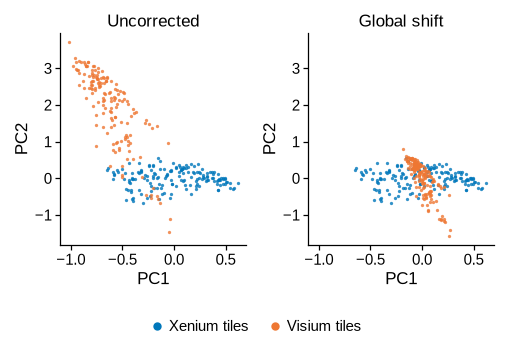

In [2]:
def panel_a(fig, legend=True):
    p = pd.read_csv(RES / "bias_pca.csv")
    p = p[p.direction == "v2x"]
    idx, qs = p[p.role == "index"], {c: p[(p.role == "query") & (p.corrected == c)] for c in (False, True)}
    allp = pd.concat([idx, *qs.values()])
    pad = 0.05
    lim = [(allp[c].min() - pad * np.ptp(allp[c]), allp[c].max() + pad * np.ptp(allp[c])) for c in ("PC1", "PC2")]
    W, _ = ps.size_mm(fig)
    w = W / 2
    for j, (corr, title) in enumerate(((False, "Uncorrected"), (True, "Global shift"))):
        ax = ps.axes(fig, left=j * w + 9.0, right=(1 - j) * w + 1.5, top=TOP, bottom=BOTTOM + (LEG if legend else 0))
        ax.scatter(idx.PC1, idx.PC2, s=2.5, c=PLATFORM["Xenium"], lw=0, alpha=0.8)
        ax.scatter(qs[corr].PC1, qs[corr].PC2, s=2.5, c=PLATFORM["Visium"], lw=0, alpha=0.8)
        ax.set_xlim(*lim[0])
        ax.set_ylim(*lim[1])
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_title(title, fontsize=ps.LABEL_PT, pad=3)
    if legend:
        platform_legend(fig)


def platform_legend(fig):
    fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=3, color=PLATFORM[m], label=f"{m} tiles")
                        for m in ("Xenium", "Visium")], loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2,
               handletextpad=0.2)


fig = ps.panel(W_A, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · Tissue agreement (seed 0, global shift)

figures/figS4_cross_platform/panels/B.pdf/.png: 48 x 58 mm, 0.0 / 0.3 MB


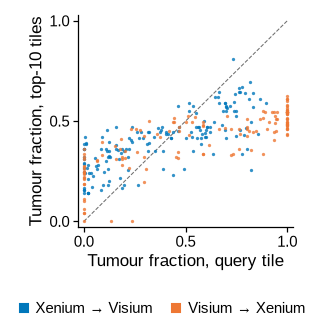

In [3]:
def direction_legend(fig):
    fig.legend(handles=[Line2D([], [], ls="", marker="s", ms=4, color=DIRECTION[d], label=DIRECTION_LABEL[d])
                        for d in ("x2v", "v2x")], loc="lower center", bbox_to_anchor=(0.5, 0.0), ncol=2,
               handletextpad=0.2, columnspacing=1.0)


def panel_b(fig, legend=True):
    t = pd.read_csv(RES / "tissue_seed0.csv")
    ax = ps.axes(fig, left=10.0, bottom=BOTTOM + (LEG if legend else 0), right=1.5, top=TOP)
    ax.plot([0, 1], [0, 1], ls="--", lw=0.5, color=ps.MUTED, zorder=1)
    for d in ("x2v", "v2x"):
        g = t[t.direction == d]
        ax.scatter(g.query_tumour, g.hits_tumour, s=2.5, c=DIRECTION[d], lw=0, alpha=0.8, zorder=2)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("Tumour fraction, query tile")
    ax.set_ylabel("Tumour fraction, top-10 tiles")
    if legend:
        direction_legend(fig)


fig = ps.panel(W_B, H); panel_b(fig); ps.save_panel(fig, FIG, "B")

## C · Correction ablation

figures/figS4_cross_platform/panels/C.pdf/.png: 48 x 58 mm, 0.0 / 0.2 MB


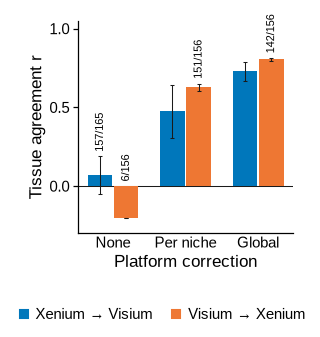

In [4]:
def panel_c(fig, legend=True):
    t = pd.read_csv(RES / "tissue.csv").set_index(["direction", "method"])
    arms = [("spindle_none", "None"), ("spindle_per_niche", "Per niche"), ("spindle_global", "Global")]
    ax = ps.axes(fig, left=10.0, bottom=BOTTOM + (LEG if legend else 0), right=1.5, top=TOP)
    w = 0.36
    for j, d in enumerate(("x2v", "v2x")):
        x = np.arange(len(arms)) + (j - 0.5) * w
        m = [t.loc[(d, a), "tissue_r_mean"] for a, _ in arms]
        s = [t.loc[(d, a), "tissue_r_std"] for a, _ in arms]
        ax.bar(x, m, w * 0.95, color=DIRECTION[d], lw=0, zorder=2)
        ax.errorbar(x, m, yerr=s, fmt="none", ecolor=ps.INK, elinewidth=0.5, capsize=1.0, capthick=0.5, zorder=3)
        for xi, (a, _), mi, si in zip(x, arms, m, s):  # queries Spindle returned no tile for are left out of r
            n_q, n_none = t.loc[(d, a), "n_query_mean"], t.loc[(d, a), "n_no_hits_mean"]
            if n_none >= 0.5:
                ax.text(xi, max(mi, 0) + si + 0.03, f"{n_q - n_none:.0f}/{n_q:.0f}", rotation=90, ha="center",
                        va="bottom", fontsize=5.5)
    ax.axhline(0, color=ps.INK, lw=0.5, zorder=1)
    ax.set_xticks(range(len(arms)))
    ax.set_xticklabels([l for _, l in arms])
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(-0.3, 1.05)
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("Platform correction")
    ax.set_ylabel("Tissue agreement r")
    if legend:
        direction_legend(fig)


fig = ps.panel(W_C, H); panel_c(fig); ps.save_panel(fig, FIG, "C")

## Full figure

figures/figS4_cross_platform/figS4_cross_platform.pdf/.png: 180 x 64 mm, 0.0 / 0.9 MB


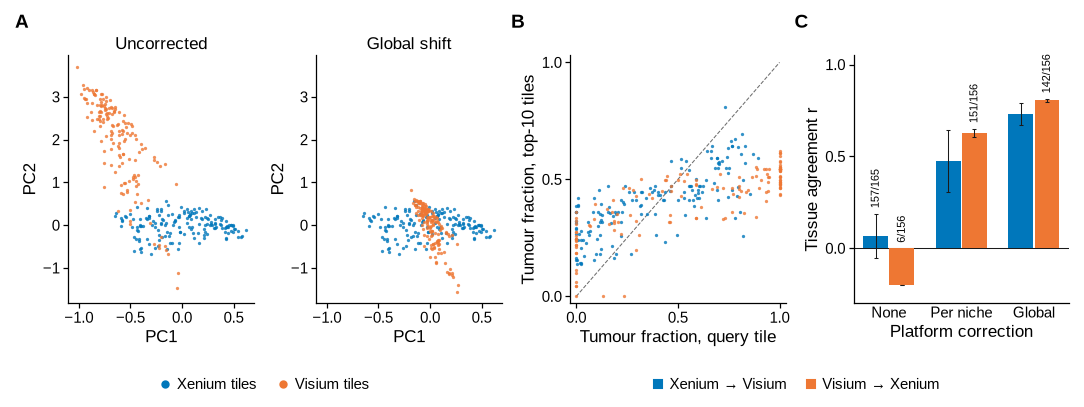

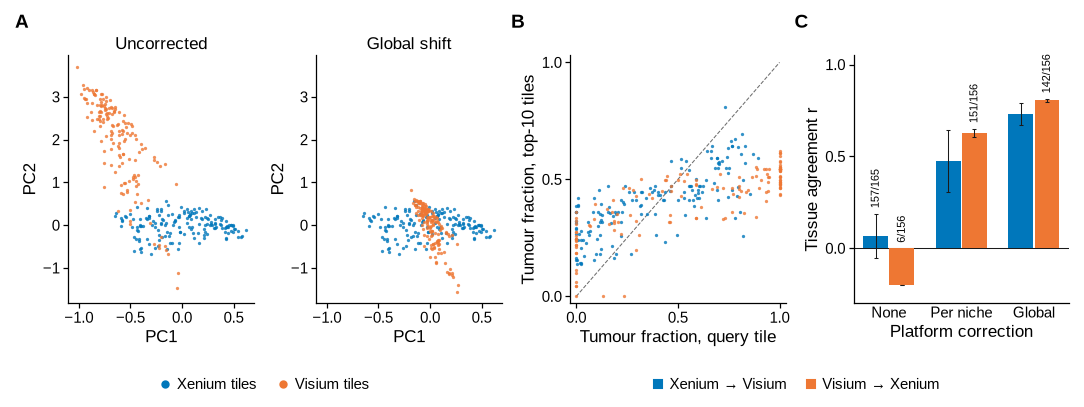

In [5]:
page = ps.page(180, H + LEG)
panel_a(ps.place(page, "A", 0, 0, W_A, H), legend=False)
panel_b(ps.place(page, "B", W_A, 0, W_B, H), legend=False)
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H), legend=False)
platform_legend(ps.place(page, None, 0, H, W_A, LEG))
direction_legend(ps.place(page, None, W_A, H, W_B + W_C, LEG))
ps.save_figure(page, FIG)
page